# Movimiento de la cabeza antes y después de la realineación (en milímetros)

Este notebook tiene dos partes:

**Parte A — los 46 sujetos (rápida).** Usa el `motion.csv` que guardó el preprocesamiento: el **FD** (*framewise displacement*, en mm) de cada volumen respecto al anterior, medido sobre los datos crudos. Es el movimiento que la realineación tuvo que corregir.

**Parte B — antes vs. después (para sujetos que elijas).** Como el 4D realineado se borró para ahorrar disco, aquí se **vuelve a estimar** el movimiento: primero sobre el BOLD crudo (**antes**: traslaciones en mm, rotaciones en grados y FD) y luego sobre la serie ya realineada (**después**: movimiento residual, que debería ser mucho menor). Es más lento, por eso se hace solo para unos pocos sujetos y los resultados se guardan en disco.

⚠️ El FD es el desplazamiento entre volúmenes consecutivos, por lo que **depende del TR**: con TR 0.61 s hay menos movimiento entre volúmenes que con TR 2.5 s. Los sanos del proyecto son TR 2.5 s y casi todos los pacientes TR 0.61 s, así que **comparar el FD por volumen entre grupos está confundido por el TR**; menciónalo en el informe.

## 1. Rutas e importaciones

In [1]:
import gc, time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import nibabel as nib
import ants

RAIZ        = Path.cwd().resolve()                 # el notebook esta en Proyecto_U3
CSV_SUJETOS = RAIZ / "sujetos_46.csv"
DATA_DIR    = RAIZ / "ds005366_subset"             # BOLD crudos
OUT_DIR     = RAIZ / "derivatives_unidad3"         # preprocesados
FIG_DIR     = OUT_DIR / "qc_movimiento"
FIG_DIR.mkdir(parents=True, exist_ok=True)

UMBRAL_FD_MM = 0.5     # linea de referencia en las graficas
for n, p in [("CSV", CSV_SUJETOS), ("DATA", DATA_DIR), ("OUT", OUT_DIR)]:
    print(f"{n:5s} {'OK ' if p.exists() else 'NO EXISTE'} {p}")
df = pd.read_csv(CSV_SUJETOS)

CSV   OK  C:\Users\Lenovo\Documents\Paulina 9S\P Imagenes\Proyecto_U3\sujetos_46.csv
DATA  OK  C:\Users\Lenovo\Documents\Paulina 9S\P Imagenes\Proyecto_U3\ds005366_subset
OUT   OK  C:\Users\Lenovo\Documents\Paulina 9S\P Imagenes\Proyecto_U3\derivatives_unidad3


## Parte A — FD de los 46 sujetos (sobre datos crudos)

In [2]:
filas = []
fd_series = {}
for _, r in df.iterrows():
    m = OUT_DIR / r["sub"] / "motion.csv"
    if not m.exists():
        continue
    fd = pd.read_csv(m)["FD"].fillna(0).to_numpy(float)
    fd_series[r["sub"]] = fd
    filas.append(dict(sub=r["sub"], grupo=r["grupo"], sex=r["sex"], age=r["age"], TR=r["TR"], n_vol=len(fd),
                      FD_medio_mm=fd.mean(), FD_max_mm=fd.max(),
                      pct_vol_FD_gt_0_5=(fd > 0.5).mean() * 100, pct_vol_FD_gt_1=(fd > 1.0).mean() * 100))
resumenA = pd.DataFrame(filas)
resumenA.to_csv(FIG_DIR / "resumen_FD_46.csv", index=False)
print(resumenA.groupby("grupo")[["FD_medio_mm", "FD_max_mm", "pct_vol_FD_gt_0_5"]].agg(["mean", "median"]).round(2))
resumenA.sort_values("FD_medio_mm", ascending=False).head(10).round(2)

          FD_medio_mm        FD_max_mm        pct_vol_FD_gt_0_5       
                 mean median      mean median              mean median
grupo                                                                 
epilepsia        0.21   0.20      0.86   0.68              4.25   1.02
sano             0.07   0.06      0.27   0.24              0.03   0.00


,sub,grupo,sex,age,TR,n_vol,FD_medio_mm,FD_max_mm,pct_vol_FD_gt_0_5,pct_vol_FD_gt_1
31,sub-019,epilepsia,F,14,1.85,145,0.52,2.47,39.31,6.21
35,sub-025,epilepsia,F,19,0.61,442,0.35,1.85,14.48,3.17
34,sub-023,epilepsia,F,47,0.61,442,0.26,0.71,1.81,0.00
36,sub-030,epilepsia,M,13,0.61,442,0.23,0.81,1.81,0.00
44,sub-076,epilepsia,M,25,1.85,145,0.22,0.68,3.45,0.00
43,sub-072,epilepsia,M,11,0.61,442,0.21,1.57,2.49,1.13
41,sub-066,epilepsia,F,50,0.61,690,0.21,0.96,1.59,0.00
45,sub-155,epilepsia,M,16,0.61,690,0.20,0.59,0.43,0.00
30,sub-009,epilepsia,F,17,0.61,690,0.20,0.86,1.88,0.00
32,sub-020,epilepsia,F,15,0.61,442,0.16,0.39,0.00,0.00


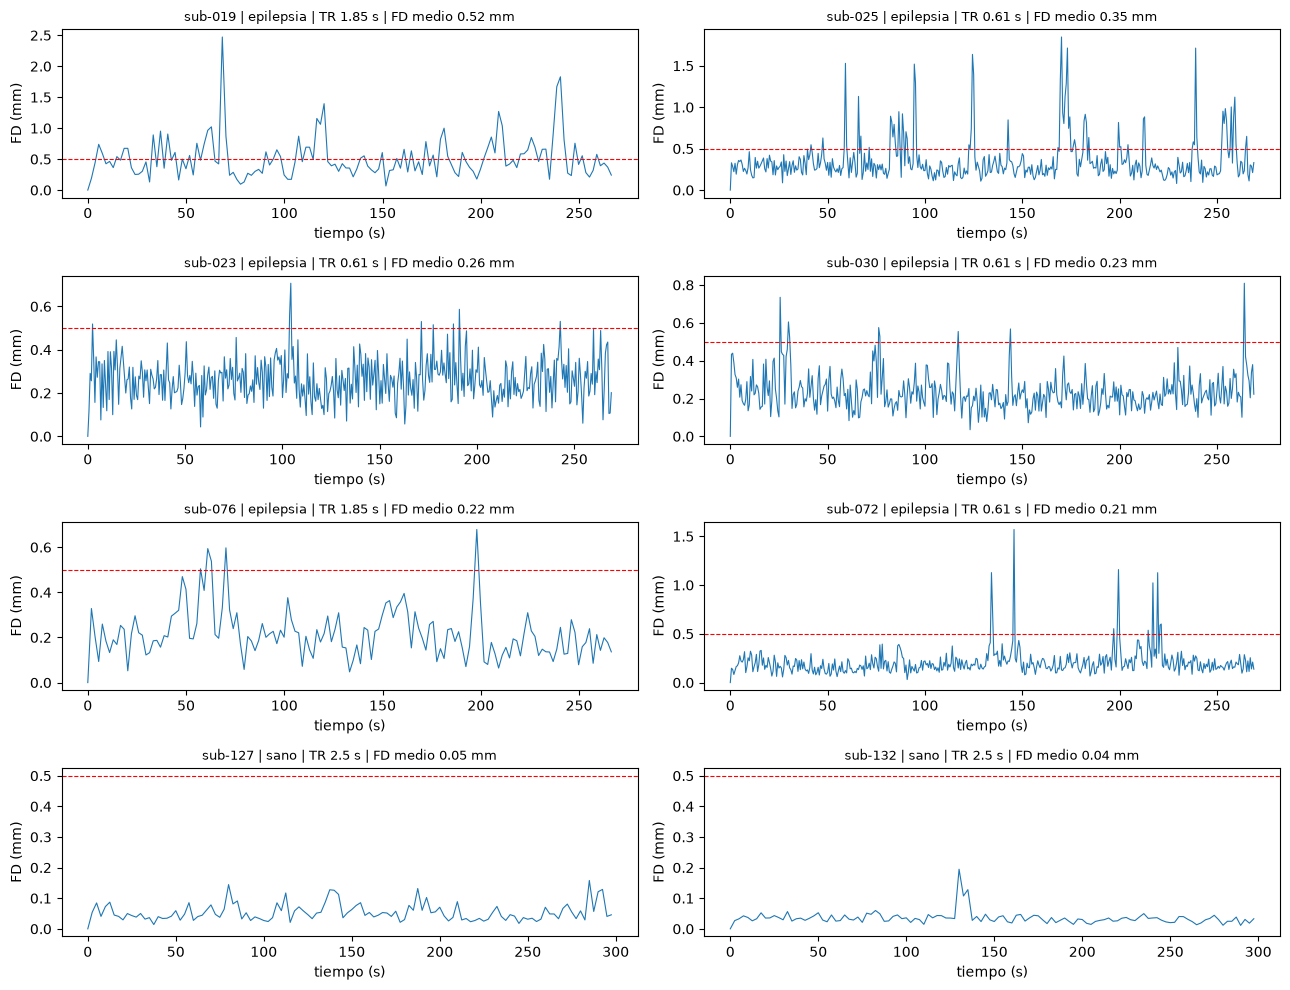

In [3]:
# Series de FD (mm) en el tiempo: los sujetos con mas movimiento + los de menos movimiento
orden = resumenA.sort_values("FD_medio_mm", ascending=False)
elegidos = list(orden["sub"].head(6)) + list(orden["sub"].tail(2))
fig, axes = plt.subplots(4, 2, figsize=(13, 10), sharey=False)
for ax, s in zip(axes.ravel(), elegidos):
    r = resumenA[resumenA["sub"] == s].iloc[0]
    t = np.arange(len(fd_series[s])) * r["TR"]
    ax.plot(t, fd_series[s], lw=0.8)
    ax.axhline(UMBRAL_FD_MM, color="r", ls="--", lw=0.8)
    ax.set_title(f"{s} | {r['grupo']} | TR {r['TR']} s | FD medio {r['FD_medio_mm']:.2f} mm", fontsize=9)
    ax.set_xlabel("tiempo (s)"); ax.set_ylabel("FD (mm)")
fig.tight_layout()
fig.savefig(FIG_DIR / "FD_series_seleccion.png", dpi=120)
plt.show()

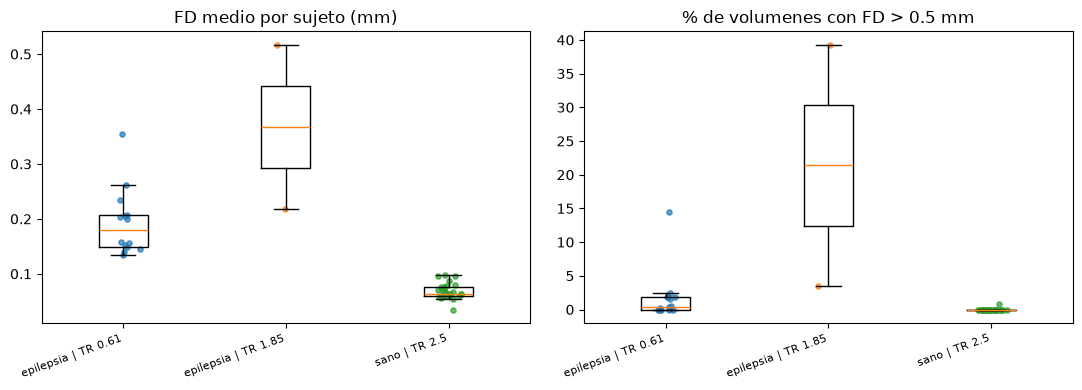

In [4]:
# Resumen por grupo, separado por protocolo (TR) para no mezclar peras con manzanas
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
resumenA["protocolo"] = resumenA["grupo"] + " | TR " + resumenA["TR"].astype(str)
etiquetas = sorted(resumenA["protocolo"].unique())
for ax, col, tit in zip(axes, ["FD_medio_mm", "pct_vol_FD_gt_0_5"],
                        ["FD medio por sujeto (mm)", "% de volumenes con FD > 0.5 mm"]):
    datos = [resumenA.loc[resumenA["protocolo"] == e, col] for e in etiquetas]
    ax.boxplot(datos, showfliers=False)
    for i, d in enumerate(datos, 1):
        ax.scatter(np.random.normal(i, 0.05, len(d)), d, s=14, alpha=0.7)
    ax.set_xticks(range(1, len(etiquetas) + 1)); ax.set_xticklabels(etiquetas, rotation=20, ha="right", fontsize=8)
    ax.set_title(tit)
fig.tight_layout()
fig.savefig(FIG_DIR / "FD_por_grupo_y_TR.png", dpi=120)
plt.show()

## Parte B — Antes vs. después de la realineación (mm y grados)

Las funciones siguientes re-estiman el movimiento con una realineación rígida (6 parámetros).
- **Traslaciones** `tx, ty, tz`: milímetros (ejes del espacio físico de ANTs).
- **Rotaciones** `rx, ry, rz`: grados.
- **FD**: milímetros, con el mismo criterio de ANTsPy que en el preprocesamiento (radio de 50 mm).

In [5]:
def _parametros(path_transform):
    """Traslacion (mm) y rotacion (grados) de una transformacion rigida guardada por ANTs."""
    if not isinstance(path_transform, str):
        return [np.nan] * 6
    p = np.asarray(ants.read_transform(path_transform).parameters, dtype=float)
    if len(p) == 12:                       # matriz 3x3 + traslacion
        A, t = p[:9].reshape(3, 3), p[9:12]
        rx = np.degrees(np.arctan2(A[2, 1], A[2, 2]))
        ry = np.degrees(-np.arcsin(np.clip(A[2, 0], -1, 1)))
        rz = np.degrees(np.arctan2(A[1, 0], A[0, 0]))
    elif len(p) == 6:                      # Euler: 3 angulos (rad) + 3 traslaciones
        rx, ry, rz = np.degrees(p[:3]); t = p[3:6]
    else:
        return [np.nan] * 6
    return [*t, rx, ry, rz]


def estimar_movimiento(img4d, tr):
    """Devuelve (DataFrame de movimiento, imagen corregida)."""
    res = ants.motion_correction(img4d, type_of_transform="Rigid")
    filas = []
    for k, tx in enumerate(res["motion_parameters"]):
        ruta = tx[0] if isinstance(tx, (list, tuple)) and len(tx) else tx
        filas.append(_parametros(ruta))
    mov = pd.DataFrame(filas, columns=["tx_mm", "ty_mm", "tz_mm", "rx_deg", "ry_deg", "rz_deg"])
    mov["FD_mm"] = np.asarray(res["FD"], dtype=float)
    mov["tiempo_s"] = np.arange(len(mov)) * tr
    return mov, res["motion_corrected"]

In [6]:
def antes_despues(sub, max_vol=300):
    """Re-estima el movimiento ANTES (BOLD crudo) y DESPUES (serie realineada). Guarda CSV y figuras."""
    r = df[df["sub"] == sub].iloc[0]
    tr = float(r["TR"])
    csv = OUT_DIR / sub / "motion_detalle_antes_despues.csv"
    bold = DATA_DIR / sub / f"ses-{r['ses']}" / r["bold_file"]
    if not bold.exists():
        bold = Path(str(bold) + ".gz")

    t0 = time.time()
    raw = ants.image_read(str(bold))
    if max_vol and raw.shape[3] > max_vol:                      # recorta para ir mas rapido
        raw = ants.from_numpy(raw.numpy()[..., :max_vol], spacing=raw.spacing, origin=raw.origin, direction=raw.direction)
    print(f"[{sub}] {raw.shape[3]} volumenes, TR {tr} s")

    print("   antes: estimando movimiento del BOLD crudo...")
    antes, corregida = estimar_movimiento(raw, tr)
    print("   despues: estimando movimiento residual de la serie realineada...")
    despues, _ = estimar_movimiento(corregida, tr)

    out = pd.concat([antes.add_suffix("_antes"), despues.drop(columns="tiempo_s").add_suffix("_despues")], axis=1)
    out.to_csv(csv, index=False)

    # --- Figura 1: traslaciones, rotaciones y FD ---
    fig = plt.figure(figsize=(13, 9))
    gs = fig.add_gridspec(3, 2)
    ejes = {}
    for j, (nombre, d) in enumerate([("ANTES (crudo)", antes), ("DESPUES (realineado)", despues)]):
        ejes[(0, j)] = fig.add_subplot(gs[0, j], sharey=ejes.get((0, 0)))
        ejes[(1, j)] = fig.add_subplot(gs[1, j], sharey=ejes.get((1, 0)))
        for c_, col in zip("xyz", ["tx_mm", "ty_mm", "tz_mm"]):
            ejes[(0, j)].plot(d["tiempo_s"], d[col], lw=0.9, label=f"t{c_}")
        for c_, col in zip("xyz", ["rx_deg", "ry_deg", "rz_deg"]):
            ejes[(1, j)].plot(d["tiempo_s"], d[col], lw=0.9, label=f"r{c_}")
        ejes[(0, j)].set_title(f"{nombre}: traslaciones"); ejes[(1, j)].set_title(f"{nombre}: rotaciones")
        ejes[(0, j)].set_ylabel("mm"); ejes[(1, j)].set_ylabel("grados")
        ejes[(0, j)].legend(fontsize=7, ncol=3); ejes[(1, j)].legend(fontsize=7, ncol=3)
    ax = fig.add_subplot(gs[2, :])
    ax.plot(antes["tiempo_s"], antes["FD_mm"], label=f"antes (FD medio {antes['FD_mm'].mean():.2f} mm)", lw=0.9)
    ax.plot(despues["tiempo_s"], despues["FD_mm"], label=f"despues (FD medio {despues['FD_mm'].mean():.2f} mm)", lw=0.9)
    ax.axhline(UMBRAL_FD_MM, color="r", ls="--", lw=0.8)
    ax.set_xlabel("tiempo (s)"); ax.set_ylabel("FD (mm)"); ax.legend(); ax.set_title("Framewise displacement")
    fig.suptitle(f"{sub} ({r['grupo']}, {r['age']} anios)", fontsize=12)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{sub}_movimiento_antes_despues.png", dpi=120)
    plt.show()

    # --- Figura 2: media y desviacion estandar temporal (se nota el desenfoque por movimiento) ---
    a_raw, a_cor = raw.numpy(), corregida.numpy()
    k = a_raw.shape[2] // 2
    fig, ax = plt.subplots(2, 2, figsize=(8, 8))
    for col, (nom, a) in enumerate([("crudo", a_raw), ("realineado", a_cor)]):
        m, s = a.mean(axis=3)[:, :, k], a.std(axis=3)[:, :, k]
        ax[0, col].imshow(m.T, cmap="gray", origin="lower"); ax[0, col].set_title(f"media temporal ({nom})")
        ax[1, col].imshow(s.T, cmap="hot", origin="lower", vmin=0, vmax=np.percentile(np.concatenate([a_raw.std(axis=3)[:, :, k].ravel(), a_cor.std(axis=3)[:, :, k].ravel()]), 99))
        ax[1, col].set_title(f"desv. estandar temporal ({nom})")
        ax[0, col].axis("off"); ax[1, col].axis("off")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{sub}_media_sd_antes_despues.png", dpi=120)
    plt.show()

    del raw, corregida, a_raw, a_cor
    gc.collect()
    print(f"   listo en {(time.time() - t0) / 60:.1f} min -> {csv.name}")
    return dict(sub=sub, grupo=r["grupo"], TR=tr, n_vol=len(antes),
                FD_medio_antes=antes["FD_mm"].mean(), FD_medio_despues=despues["FD_mm"].mean(),
                FD_max_antes=antes["FD_mm"].max(), FD_max_despues=despues["FD_mm"].max(),
                trasl_max_antes_mm=antes[["tx_mm", "ty_mm", "tz_mm"]].abs().to_numpy().max(),
                trasl_max_despues_mm=despues[["tx_mm", "ty_mm", "tz_mm"]].abs().to_numpy().max())

### Elige los sujetos
Por defecto toma el **sano** y el **paciente de epilepsia** con mayor FD medio (donde mejor se ve el efecto). Los sanos tienen 120 volúmenes (rápido); los pacientes con TR 0.61 s tienen hasta 690, por eso `MAX_VOL` recorta a los primeros 300 volúmenes para acelerar (pon `None` para usar todos). Puedes cambiar la lista a mano, por ejemplo `SUJETOS_B = ["sub-009", "sub-083"]`.

Sujetos: ['sub-103', 'sub-019']
[sub-103] 120 volumenes, TR 2.5 s
   antes: estimando movimiento del BOLD crudo...
   despues: estimando movimiento residual de la serie realineada...


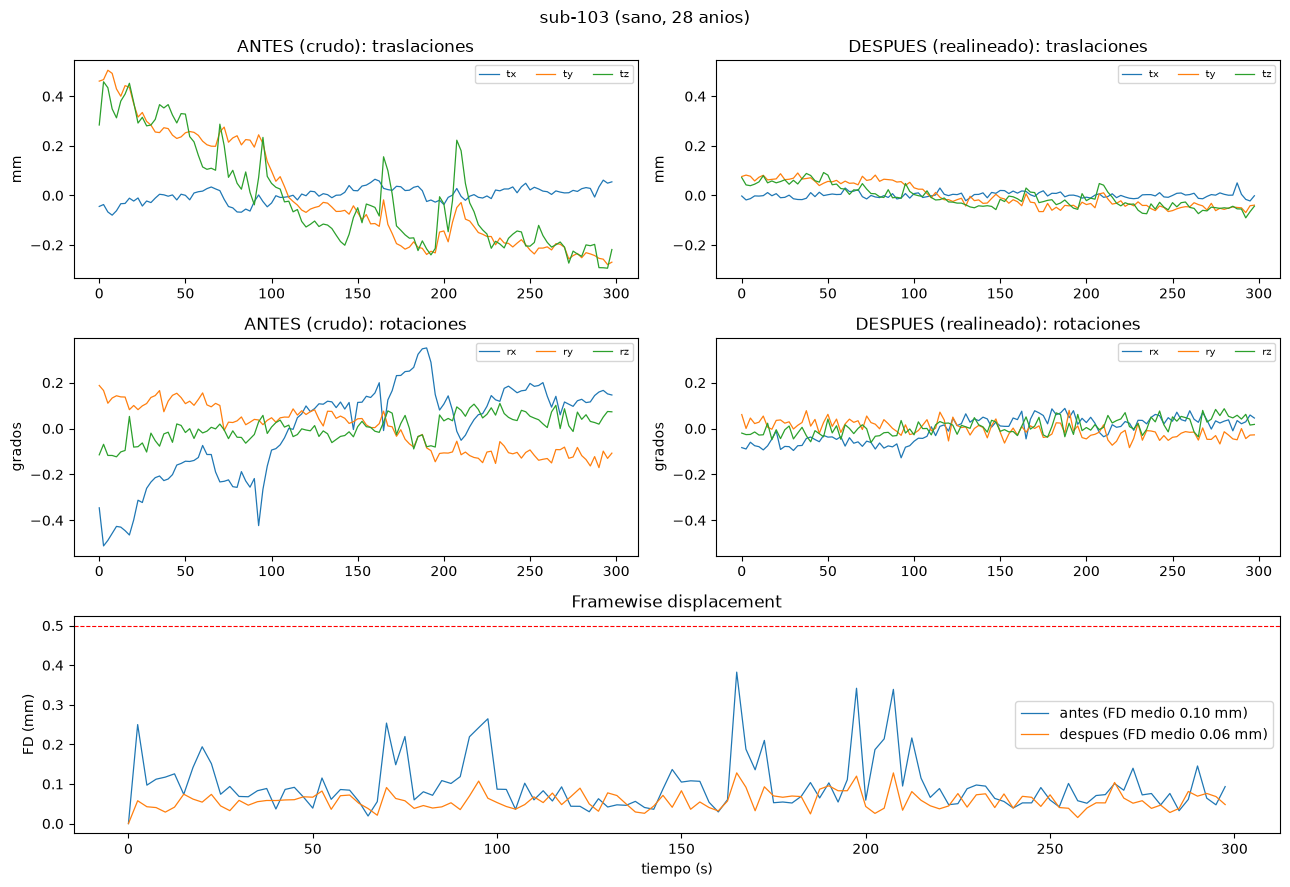

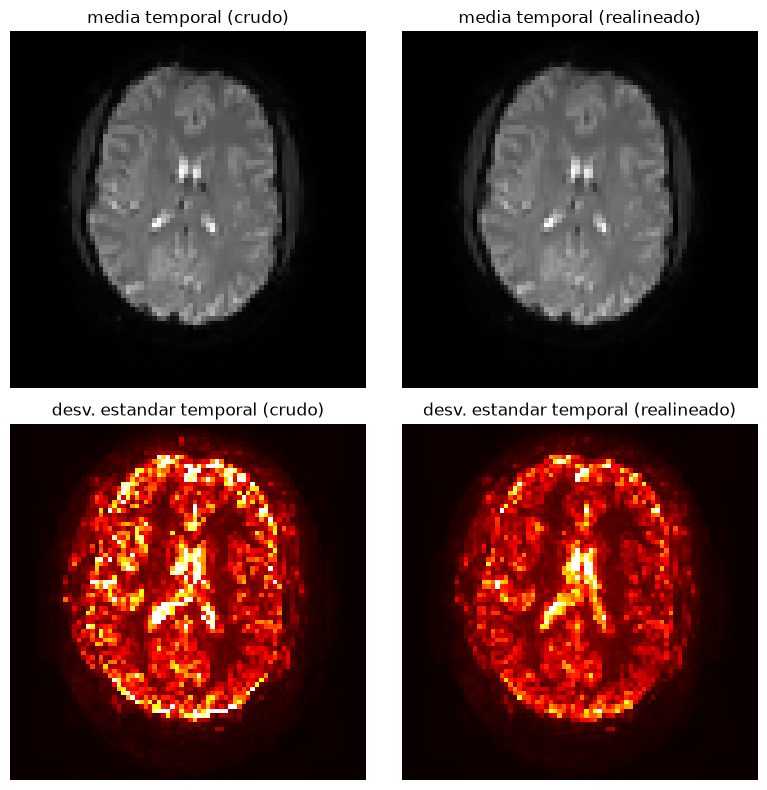

   listo en 5.9 min -> motion_detalle_antes_despues.csv
[sub-019] 145 volumenes, TR 1.85 s
   antes: estimando movimiento del BOLD crudo...
   despues: estimando movimiento residual de la serie realineada...


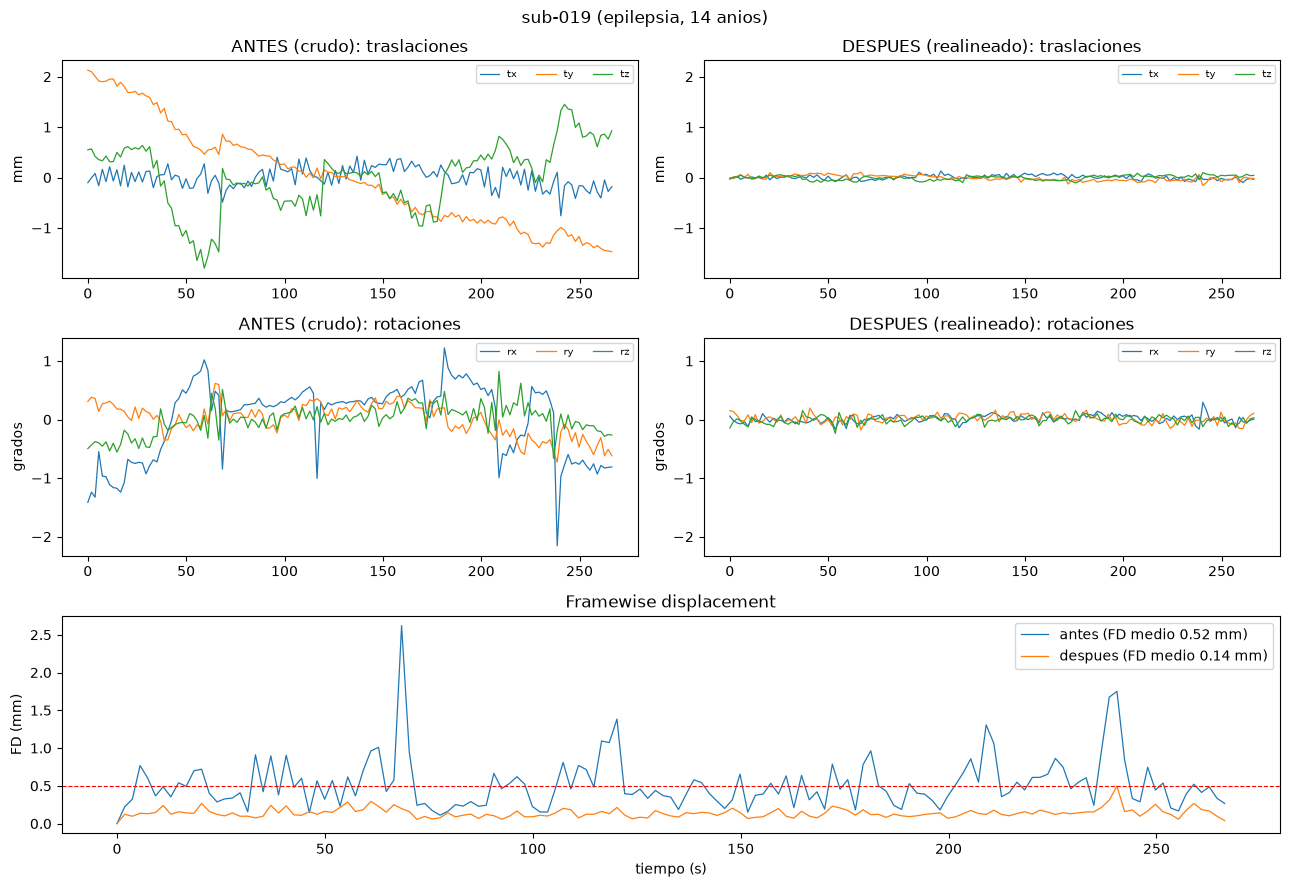

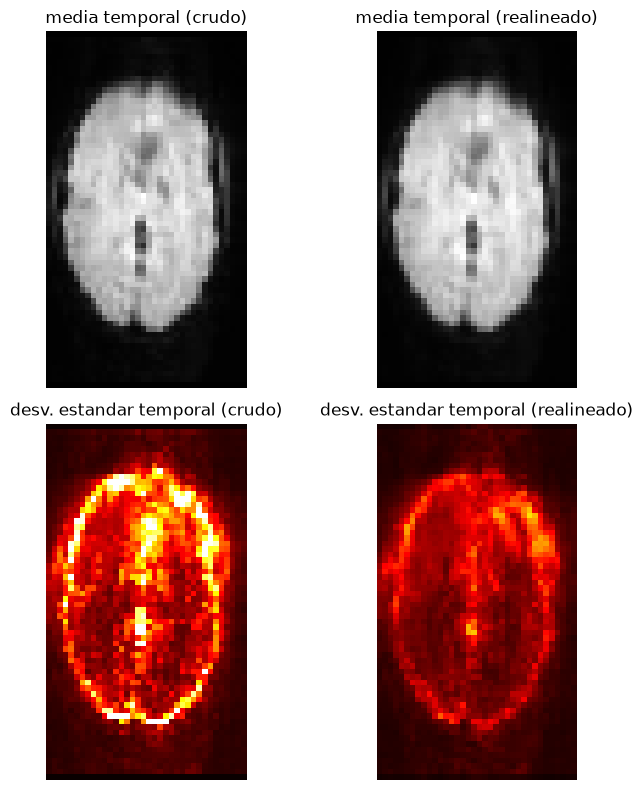

   listo en 4.5 min -> motion_detalle_antes_despues.csv


,sub,grupo,TR,n_vol,FD_medio_antes,FD_medio_despues,FD_max_antes,FD_max_despues,trasl_max_antes_mm,trasl_max_despues_mm
0,sub-103,sano,2.50,120,0.10,0.06,0.38,0.13,0.50,0.09
1,sub-019,epilepsia,1.85,145,0.52,0.14,2.62,0.49,2.13,0.16


In [7]:
MAX_VOL = 300
SUJETOS_B = [
    resumenA[resumenA.grupo == "sano"].sort_values("FD_medio_mm").iloc[-1]["sub"],
    resumenA[resumenA.grupo == "epilepsia"].sort_values("FD_medio_mm").iloc[-1]["sub"],
]
print("Sujetos:", SUJETOS_B)
resultados_B = [antes_despues(s, max_vol=MAX_VOL) for s in SUJETOS_B]
tabla_B = pd.DataFrame(resultados_B).round(2)
tabla_B.to_csv(FIG_DIR / "resumen_antes_despues.csv", index=False)
tabla_B

**Cómo leerlo.** En "antes", las traslaciones y rotaciones muestran cuánto se movió la cabeza (mm y grados) y el FD marca los saltos bruscos. En "después", las curvas deberían quedar cerca de cero: lo que queda es ruido de la estimación, no movimiento real. En la figura de media/desviación estándar, el crudo se ve más borroso y con bordes brillantes en la desviación (movimiento); el realineado debería verse más nítido y con menos borde.
La realineación corrige el movimiento rígido entre volúmenes, pero **no elimina por completo los efectos del movimiento sobre la señal**; por eso el GLM incluye el FD como regresor.